# Telco Customer Churn Prediction using Random Forest
**Project:** Random Forest Machine Learning Project  
**Problem type:** Binary Classification (will a customer churn? Yes / No)  
**Dataset source (Kaggle):** *Telco Customer Churn* by IBM / BlastChar — https://www.kaggle.com/datasets/blastchar/telco-customer-churn  
**File used:** `WA_Fn-UseC_-Telco-Customer-Churn.csv` (7,043 real customer records, 21 columns)

Place the CSV in the same folder as this notebook and run all cells.

## 1. Import required libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_style("whitegrid")

## 2. Load the dataset

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Basic data exploration

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Summary statistics of numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


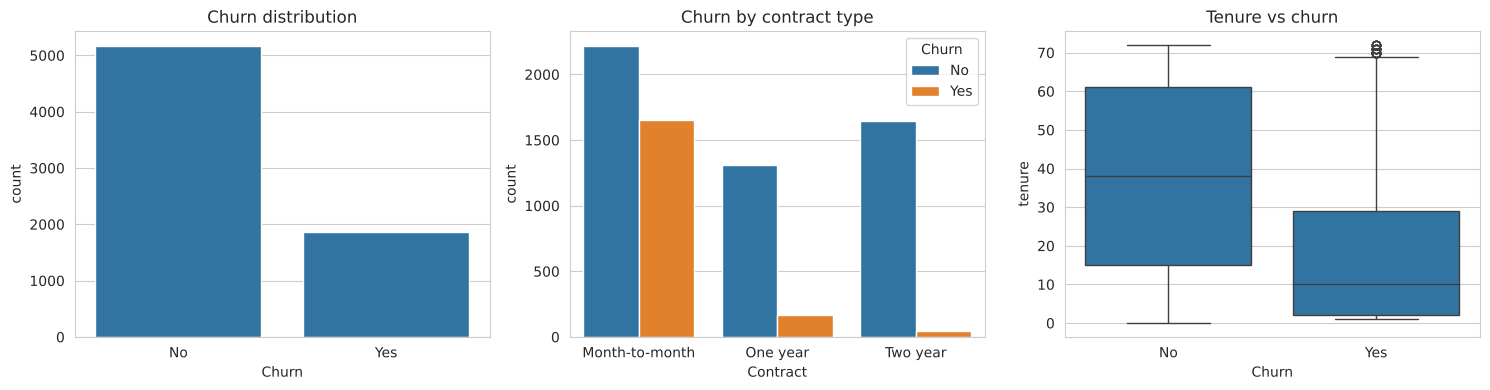

In [5]:
# Target distribution - note the class imbalance (~73% No vs ~27% Yes)
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Churn", data=df, ax=ax[0])
ax[0].set_title("Churn distribution")
sns.countplot(x="Contract", hue="Churn", data=df, ax=ax[1])
ax[1].set_title("Churn by contract type")
sns.boxplot(x="Churn", y="tenure", data=df, ax=ax[2])
ax[2].set_title("Tenure vs churn")
plt.tight_layout()
plt.show()

## 4. Handle missing values
`df.isnull().sum()` shows no missing values, but `TotalCharges` is stored as text (`object`) — a sign of hidden blanks.
We convert it to numeric; blank strings become `NaN`.

In [6]:
print("Null values (before conversion):", df.isnull().sum().sum())

# Convert TotalCharges to numeric; blanks (" ") become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

# These 11 customers have tenure = 0 (brand-new customers, never billed yet),
# so their true total charges so far is 0
print(df.loc[df["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]].head())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just an identifier - it carries no predictive information
df = df.drop(columns=["customerID"])
print("Remaining nulls:", df.isnull().sum().sum())

Null values (before conversion): 0
Missing TotalCharges after conversion: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
Remaining nulls: 0


## 5. Encode categorical variables

In [7]:
# Target: Yes -> 1, No -> 0
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# One-hot encode all remaining text columns (drop_first avoids redundant columns)
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Categorical columns encoded:", cat_cols)
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Categorical columns encoded: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape after encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


## 6. Split features (X) and target (y)

In [8]:
X = df_encoded.drop(columns="Churn")
y = df_encoded["Churn"]
print("X:", X.shape, "| y:", y.shape)

X: (7043, 30) | y: (7043,)


## 7. Train-test split
80% training / 20% testing. `stratify=y` keeps the churn ratio the same in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5634, 30) | Test: (1409, 30)


## 8–9. Apply the Random Forest model and train it (baseline)

In [10]:
# Random Forest = many decision trees trained on random samples of data/features;
# the final prediction is the majority vote of all trees.
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## 10. Make predictions

In [11]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

## 11. Evaluate the model

In [12]:
def evaluate(name, y_true, y_pred, y_prob):
    res = {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1-Score":  f1_score(y_true, y_pred),
        "ROC-AUC":   roc_auc_score(y_true, y_prob),
    }
    print(f"--- {name} ---")
    for k, v in res.items():
        print(f"{k:10s}: {v:.4f}")
    return res

base_res = evaluate("Baseline Random Forest", y_test, y_pred, y_prob)
print()
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

--- Baseline Random Forest ---
Accuracy  : 0.7928
Precision : 0.6367
Recall    : 0.5107
F1-Score  : 0.5668
ROC-AUC   : 0.8264

              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.78      1409



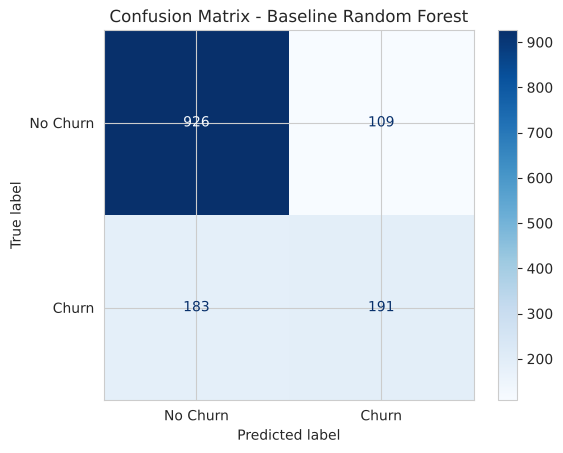

In [13]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Baseline Random Forest")
plt.show()

## 12. Feature importance

TotalCharges                      0.1935
tenure                            0.1705
MonthlyCharges                    0.1681
PaymentMethod_Electronic check    0.0381
InternetService_Fiber optic       0.0371
Contract_Two year                 0.0311
gender_Male                       0.0286
OnlineSecurity_Yes                0.0283
PaperlessBilling_Yes              0.0255
Contract_One year                 0.0232
dtype: float64


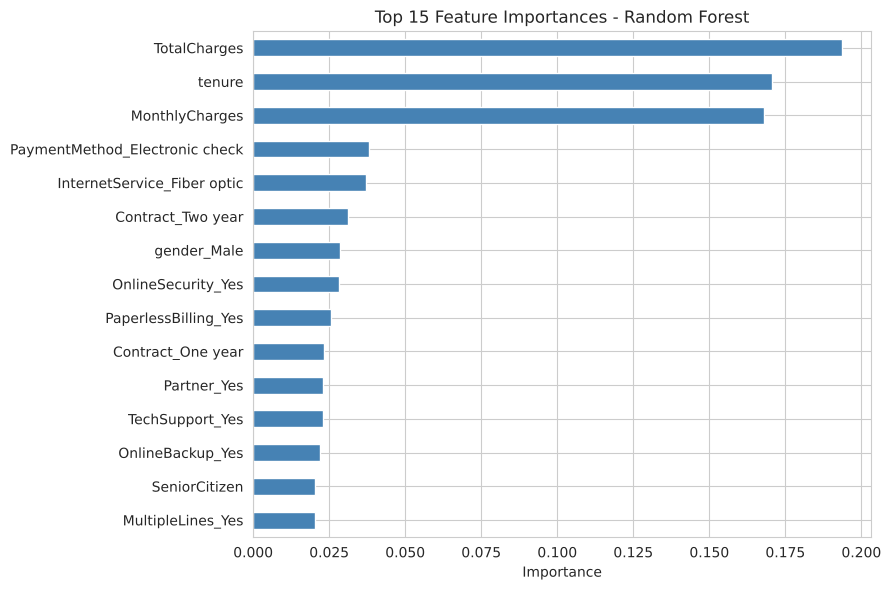

In [14]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10).round(4))

plt.figure(figsize=(9, 6))
importances.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Bonus A: Cross-validation
5-fold stratified cross-validation checks that the score isn't just luck from one particular train/test split.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf, X, y, cv=skf, scoring="accuracy", n_jobs=-1)
print("CV accuracy per fold:", cv_scores.round(4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

CV accuracy per fold: [0.7928 0.7963 0.7835 0.777  0.7798]
Mean CV accuracy: 0.7859 (+/- 0.0074)


## Bonus B: Hyperparameter tuning (GridSearchCV)
The data is imbalanced (few churners), so we also try `class_weight="balanced"`. We optimise **F1-score** because plain accuracy hides how many churners we miss.

In [16]:
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [1, 3, 5],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                    param_grid, cv=3, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")

Best parameters: {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}
Best CV F1: 0.6381


In [17]:
best_rf = grid.best_estimator_
y_pred_t = best_rf.predict(X_test)
y_prob_t = best_rf.predict_proba(X_test)[:, 1]
tuned_res = evaluate("Tuned Random Forest", y_test, y_pred_t, y_prob_t)

comparison = pd.DataFrame({"Baseline": base_res, "Tuned": tuned_res}).round(4)
comparison

--- Tuned Random Forest ---
Accuracy  : 0.7523
Precision : 0.5219
Recall    : 0.7968
F1-Score  : 0.6307
ROC-AUC   : 0.8441


,Baseline,Tuned
Accuracy,0.7928,0.7523
Precision,0.6367,0.5219
Recall,0.5107,0.7968
F1-Score,0.5668,0.6307
ROC-AUC,0.8264,0.8441


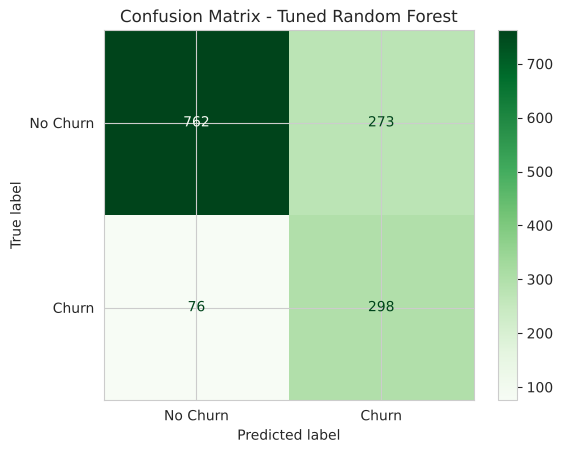

In [18]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_t),
                       display_labels=["No Churn", "Churn"]).plot(cmap="Greens")
plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

## Bonus C: Save the model

In [19]:
joblib.dump(best_rf, "churn_random_forest_model.joblib")
print("Model saved as churn_random_forest_model.joblib")

# Reload to confirm it works
loaded = joblib.load("churn_random_forest_model.joblib")
print("Reloaded model accuracy:", round(accuracy_score(y_test, loaded.predict(X_test)), 4))

Model saved as churn_random_forest_model.joblib


Reloaded model accuracy: 0.7523


## 13. Conclusion

In [20]:
print("Baseline :", {k: round(v, 3) for k, v in base_res.items()})
print("Tuned    :", {k: round(v, 3) for k, v in tuned_res.items()})
print("Top 5 features:", importances.head(5).index.tolist())

Baseline : {'Accuracy': 0.793, 'Precision': 0.637, 'Recall': 0.511, 'F1-Score': 0.567, 'ROC-AUC': 0.826}
Tuned    : {'Accuracy': 0.752, 'Precision': 0.522, 'Recall': 0.797, 'F1-Score': 0.631, 'ROC-AUC': 0.844}
Top 5 features: ['TotalCharges', 'tenure', 'MonthlyCharges', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic']


**Findings**
- The baseline Random Forest reaches **79.3% accuracy** (5-fold CV mean 78.6%), but its recall for churners is only **51%** - it misses about half of the customers who actually leave, because only ~27% of customers churn (class imbalance).
- The tuned model (`class_weight="balanced"`, `max_depth=8`, `min_samples_leaf=5`, 400 trees) trades accuracy (75.2%) for much higher **recall (79.7%)**, better **F1 (0.63 vs 0.57)** and better **ROC-AUC (0.844 vs 0.826)**. For a retention campaign, catching churners matters more than a few false alarms, so the tuned model is the better choice.
- The most important features are the three numeric ones - **TotalCharges, tenure and MonthlyCharges** - followed by **electronic-check payment, fibre-optic internet and two-year contract**. Customers with short tenure, high monthly bills, fibre-optic service and electronic-check payment are the highest churn risk, while long-term contracts reduce it.

**Business takeaway:** Encourage new customers to move to 1-2 year contracts and offer retention deals to high-bill, short-tenure customers.

**Limitations / future work:** Try other models (Gradient Boosting, XGBoost), SMOTE oversampling, and decision-threshold tuning.